# LLaMA-3.1：Loaded KV–score 趋势图

本 notebook 只生成当前这一张图：9 个带文字的主点、19 个小空心系列点、五条实测点折线、Full Attention 得分线及默认 GAS KV ±10% 灰带。

数据来自同目录 `LLaMa_KV_Score.md` 的主表和五张方法系列表；GAS 默认点使用正文精确值 1339.32。各方法按 loaded KV 从小到大排列，在当前对数横轴上直接用直线连接相邻实测点，不做平滑插值或外推。

按顺序运行全部单元即可。输出：本目录 `experiment_llama_kv_vs_score_trends.pdf` 和 `build/experiment_llama_kv_vs_score_trends.png`。代码依赖 NumPy、Matplotlib。


In [1]:
from pathlib import Path
import re

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager, patheffects, ticker
from matplotlib.patches import Patch
from IPython.display import display

# 支持从当前图目录或 SparseAttention 项目内运行。
PLOT_RELATIVE = Path("会用到的论文图与复现/fig4-KVvsScore")
DATA_NAME = "LLaMa_KV_Score.md"
search_dirs = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
DATA_SOURCE = next(
    (candidate for base in search_dirs
     for candidate in (base / DATA_NAME, base / PLOT_RELATIVE / DATA_NAME)
     if candidate.is_file()), None,
)
if DATA_SOURCE is None:
    raise FileNotFoundError(f"找不到 {DATA_NAME}；请从图目录或 SparseAttention 项目内运行。")
OUTPUT_DIR = DATA_SOURCE.parent
PREVIEW_DIR = OUTPUT_DIR / "build"
OUTPUT_NAME = "experiment_llama_kv_vs_score_trends"

for name in ("Times New Roman.ttf", "Times New Roman Bold.ttf"):
    font_path = Path("/System/Library/Fonts/Supplemental") / name
    if font_path.exists():
        font_manager.fontManager.addfont(str(font_path))


## 样式与标注：修改这一格即可

- `FIGSIZE`、`X_LIMITS`、`Y_LIMITS`：画布和坐标范围；K 表示 1000。
- `METHOD_STYLES`：各方法颜色、形状、主点面积 `main_size` 和新增空心点面积 `extra_size`。
- `ANNOTATIONS`：每个主点的最终标注设置。`offset=(dx,dy)` 单位为 pt，正数向右/向上；`fontsize` 为字号；`ha/va` 为对齐方式；`show_line` 控制引导线。GAS 加粗，四个校准点使用斜体。
- `FULL_LABEL`：Full Attention 的位置、字号及粗细。`x=0.5` 表示水平居中，`offset` 的第二个数控制文字离基准线的距离。
- `CURVE_LINE_WIDTH`：趋势线宽，自动限制为不超过 `FULL_LINE_WIDTH`；`LEGEND_FONT_SIZE` 控制灰带图例字号。

所有标注直接使用这里的设置，不再通过后续字典重复覆盖。


In [2]:
FIGSIZE = (6.0, 2.75)
DPI = 300
FONT_FAMILY = "Times New Roman"
INK = "#243136"
GRID_COLOR = "#dce2e5"
X_SCALE = "log"
X_LIMITS = (1000, 64000)
Y_LIMITS = (16, 70)
X_TICKS = [1000, 2000, 4000, 8000, 16000, 32000, 64000]
Y_TICKS = [20, 30, 40, 50, 60, 70]
X_LABEL = "Mean Group-Level Loaded KV (token slots)"
Y_LABEL = "Average Score"

FULL_COLOR = "#C70039"

FULL_LABEL = {"x": 0.5, "offset": (0, 1), "fontsize": 12, "fontweight": "bold"}
NEAR_GAS_TOLERANCE = 0.10
# BAND_COLOR = "#e9e9e9"
BAND_COLOR = "#d9d9d9"
LEGEND_FONT_SIZE = 12
# fullatt 和 其他方法的 趋势线粗细调整
FULL_LINE_WIDTH = 1.8
CURVE_LINE_WIDTH = 1.5

EXTRA_POINT_EDGE_WIDTH = 0.7
LABEL_HALO_WIDTH = 1.5

METHOD_STYLES = {
    "GAS": {"color": "#FF4D4D", "marker": "*", "main_size": 110, "extra_size": 42},
    "Quest": {"color": "#729B54", "marker": "^", "main_size": 56, "extra_size": 32},
    "DS": {"color": "#4F7192", "marker": "s", "main_size": 55, "extra_size": 32},
    "Twilight": {"color": "#C76524", "marker": "D", "main_size": 55, "extra_size": 32},
    "LessIsMore": {"color": "#8B6BB1", "marker": "o", "main_size": 55, "extra_size": 32},
}

# 每项是一处主点标注的最终设置；系列新增点不添加文字。
ANNOTATIONS = {
    "GAS": {"method": "GAS", "label": "GAS", "offset": (7, 1),
            "ha": "left", "va": "top", "fontsize": 10.0, "show_line": False},
    
    "Quest 8%": {"method": "Quest", "label": "Quest 8%", "offset": (20, -6),
                 "ha": "right", "va": "top", "fontsize": 9.0, "show_line": True},
    
    "DS 8%": {"method": "DS", "label": "DS 8%", "offset": (0, 13),
              "ha": "center", "va": "center", "fontsize": 9.0, "show_line": True},
    
    "Twilight default": {"method": "Twilight", "label": "Twilight (default)", "offset": (36, 13),
                         "ha": "center", "va": "top", "fontsize": 9.0, "show_line": False},
    
    "Quest KV-calibrated": {"method": "Quest", "label": "Quest'", "offset": (10, -4),
                            "ha": "left", "va": "center", "fontsize": 8.0, "show_line": False},
    
    "DS KV-calibrated": {"method": "DS", "label": "DS'", "offset": (6, -3),
                         "ha": "left", "va": "top", "fontsize": 8.0, "show_line": False},
    
    "Twilight KV-calibrated": {"method": "Twilight", "label": "Twilight'", "offset": (-25, 15),
                               "ha": "left", "va": "center", "fontsize": 8.0, "show_line": False},
    
    "LessIsMore default": {"method": "LessIsMore", "label": "LessIsMore (4096)", "offset": (-5, -13),
                           "ha": "left", "va": "top", "fontsize": 9.0, "show_line": True},
    
    "LessIsMore KV-calibrated": {"method": "LessIsMore", "label": "LessIsMore'", "offset": (-16, -6),
                                 "ha": "left", "va": "top", "fontsize": 8.0, "show_line": False},
}

plt.rcParams.update({
    "font.family": FONT_FAMILY, "font.serif": [FONT_FAMILY], "font.size": 9,
    "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.linewidth": 0.6, "pdf.fonttype": 42, "ps.fonttype": 42,
    "savefig.facecolor": "white", "savefig.bbox": None,
})


## 读取数据

只读取 Markdown 中的 score 和 loaded KV 原值。主表提供原有 7 个标注锚点及 Full 参考分数；方法系列表提供完整曲线点。LessIsMore 的 cali 锚点读取 `K=168` 行，Default 锚点读取 loaded KV 为 `4096` 的行，分数均直接来自 Markdown。正文的 GAS 精确 KV 同步用于主点和系列点，避免重复绘制。


In [5]:
def read_table(text):
    rows = [
        [value.strip() for value in line.strip().strip("|").split("|")]
        for line in text.splitlines() if line.strip().startswith("|")
    ]
    return [dict(zip(rows[0], values)) for values in rows[2:]]


def load_plot_data(path):
    text = path.read_text(encoding="utf-8")
    parts = re.split(r"(?m)^##[ \t]+([^\n]+)[ \t]*$", text)
    sections = {parts[i].strip(): parts[i + 1] for i in range(1, len(parts), 2)}
    records = {
        row["Method"]: {"kv": float(row["Mean loaded KV"]), "score": float(row["Macro score"])}
        for row in read_table(parts[0])
    }
    if not records or not all(
        np.isfinite(row["kv"]) and row["kv"] > 0
        and np.isfinite(row["score"]) and 0 <= row["score"] <= 100
        for row in records.values()
    ):
        raise ValueError("Loaded KV 必须为正数，score 必须为 0–100 的有限值。")

    reference = re.search(
        r"GAS reference:\s*score=([0-9.]+),\s*mean loaded KV=([0-9]+(?:\.[0-9]+)?)", text,
    )
    if reference:
        score, kv = map(float, reference.groups())
        if not np.isclose(score, records["GAS"]["score"]) or round(kv) != round(records["GAS"]["kv"]):
            raise ValueError("GAS 正文精确值与主表不一致。")
        records["GAS"]["kv"] = kv

    series = {}
    for method in METHOD_STYLES:
        method_rows = read_table(sections[method])
        points = np.array([
            [float(row["Mean loaded KV"]), float(row["Macro score"])]
            for row in method_rows
        ])
        if method == "GAS":
            gas = records["GAS"]
            anchor = (np.rint(points[:, 0]) == round(gas["kv"])) & np.isclose(points[:, 1], gas["score"])
            if np.count_nonzero(anchor) != 1:
                raise ValueError("GAS 系列表应包含唯一的默认点。")
            points[anchor, 0] = gas["kv"]
        points = points[np.argsort(points[:, 0])]
        if not np.all(np.isfinite(points)) or np.any(points[:, 0] <= 0) or not np.all(np.diff(points[:, 0]) > 0):
            raise ValueError(f"{method} 的 KV 必须为正、互不重复，所有数值必须有限。")
        if np.any((points[:, 1] < 0) | (points[:, 1] > 100)):
            raise ValueError(f"{method} 的 score 必须在 0–100 之间。")
        series[method] = points
        if method == "LessIsMore":
            # 用户指定的两个锚点；从系列表读取，避免复制分数后与 Markdown 脱节。
            anchors = {
                "LessIsMore KV-calibrated": [
                    row for row in method_rows if row["Method"].replace(" ", "") == "K=168"
                ],
                "LessIsMore default": [
                    row for row in method_rows
                    if np.isclose(float(row["Mean loaded KV"]), 4096, rtol=0, atol=1e-8)
                ],
            }
            for name, matches in anchors.items():
                if len(matches) != 1:
                    raise ValueError(f"LessIsMore 系列表应包含唯一的 {name} 点。")
                records[name] = {
                    "kv": float(matches[0]["Mean loaded KV"]),
                    "score": float(matches[0]["Macro score"]),
                }
    return records, series


records, series = load_plot_data(DATA_SOURCE)


## 绘图并导出

下方仅有一个绘图函数。运行最后一格显示当前图，并导出 PDF 和 300 dpi PNG；画布保持当前 6.0 × 2.75 英寸，不裁切。


In [6]:
def plot_llama_kv_vs_score(records, series):
    fig, ax = plt.subplots(figsize=FIGSIZE)
    fig.subplots_adjust(left=0.11, right=0.965, bottom=0.21, top=0.95)
    ax.set_xscale(X_SCALE)
    ax.set(xlim=X_LIMITS, ylim=Y_LIMITS, yticks=Y_TICKS)
    ax.set_xticks(X_TICKS)
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda value, _: f"{value / 1000:g}K"))
    ax.xaxis.set_minor_locator(ticker.NullLocator())
    ax.set_axisbelow(True)
    ax.grid(axis="y", color=GRID_COLOR, linewidth=0.5, alpha=0.8)

    band = records["GAS"]["kv"] * np.array([1 - NEAR_GAS_TOLERANCE, 1 + NEAR_GAS_TOLERANCE])
    ax.axvspan(*band, color=BAND_COLOR, linewidth=0, zorder=0)
    full_score = records["Full attention"]["score"]
    ax.axhline(full_score, color=FULL_COLOR, linestyle=(0, (4, 3)), linewidth=FULL_LINE_WIDTH, zorder=2)
    ax.annotate(
        f"Full Attention (259K, {full_score:.2f})", xy=(FULL_LABEL["x"], full_score),
        xycoords=("axes fraction", "data"), xytext=FULL_LABEL["offset"], textcoords="offset points",
        ha="center", va="bottom", fontsize=FULL_LABEL["fontsize"],
        fontweight=FULL_LABEL["fontweight"], color=FULL_COLOR,
    )

    # 按 KV 排序的实测点直接连成折线；标注锚点只绘制一次。
    for method, points in series.items():
        kv, score = points[:, 0], points[:, 1]
        style = METHOD_STYLES[method]
        ax.plot(
            kv, score, color=style["color"],
            linewidth=min(CURVE_LINE_WIDTH, FULL_LINE_WIDTH), zorder=2.5,
        )
        is_anchor = np.zeros(len(points), dtype=bool)
        for name, label_style in ANNOTATIONS.items():
            if label_style["method"] == method:
                anchor = records[name]
                is_anchor |= (
                    np.isclose(kv, anchor["kv"], rtol=0, atol=0.51)
                    & np.isclose(score, anchor["score"], rtol=0, atol=1e-8)
                )
        ax.scatter(
            kv[~is_anchor], score[~is_anchor], s=style["extra_size"], marker=style["marker"],
            facecolor="white", edgecolor=style["color"], linewidth=EXTRA_POINT_EDGE_WIDTH, zorder=3.5,
            clip_on=False,  # 保留紧邻左边界的 1024-KV 点的完整轮廓。
        )

    # 9 个主点及其文字；GAS 最后绘制。
    for name in sorted(ANNOTATIONS, key=lambda name: name == "GAS"):
        row, label_style = records[name], ANNOTATIONS[name]
        style = METHOD_STYLES[label_style["method"]]
        is_gas = name == "GAS"
        calibrated = name.endswith("KV-calibrated")
        ax.scatter(
            row["kv"], row["score"], s=style["main_size"], marker=style["marker"],
            facecolor="white" if calibrated else style["color"],
            edgecolor=style["color"], linewidth=0.9, zorder=5 if is_gas else 4,
        )
        ax.annotate(
            f"{label_style['label']}\n({row['kv']:.0f}, {row['score']:.2f})",
            xy=(row["kv"], row["score"]), xytext=label_style["offset"], textcoords="offset points",
            ha=label_style["ha"], va=label_style["va"], fontsize=label_style["fontsize"],
            fontweight="bold" if is_gas else "normal", fontstyle="italic" if calibrated else "normal",
            color=style["color"], linespacing=1.1, zorder=6,
            arrowprops=(
                {"arrowstyle": "-", "color": style["color"], "lw": 0.5, "shrinkA": 2, "shrinkB": 4}
                if label_style["show_line"] else None
            ),
            path_effects=[patheffects.withStroke(linewidth=LABEL_HALO_WIDTH, foreground="white")],
        )

    ax.set_xlabel(X_LABEL, labelpad=2, fontdict={"size": 12, "weight": "bold", "fontfamily": "Times New Roman"})
    ax.set_ylabel(Y_LABEL, labelpad=2, fontdict={"size": 12, "weight": "bold", "fontfamily": "Times New Roman"})
    ax.tick_params(axis="both", length=3, pad=3)
    for spine in ax.spines.values():
        spine.set_color(INK)
        spine.set_linewidth(0.6)
    ax.legend(
        handles=[Patch(facecolor=BAND_COLOR, edgecolor="none", label=f"Within ±{NEAR_GAS_TOLERANCE:.0%} of default GAS KV")],
        loc="lower right", borderaxespad=0.8, frameon=True,
        prop={"family": FONT_FAMILY, "size": 12}, handlelength=1.6, borderpad=0.3,
    )
    return fig, ax


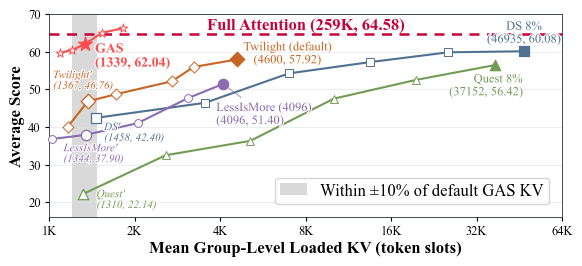

PDF: /Users/linshengle/Documents/2026/SparseAttention/会用到的论文图与复现/fig4-KVvsScore/experiment_llama_kv_vs_score_trends.pdf
PNG: /Users/linshengle/Documents/2026/SparseAttention/会用到的论文图与复现/fig4-KVvsScore/build/experiment_llama_kv_vs_score_trends.png


In [7]:
fig, ax = plot_llama_kv_vs_score(records, series)
display(fig)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PREVIEW_DIR.mkdir(parents=True, exist_ok=True)
pdf_path = OUTPUT_DIR / f"{OUTPUT_NAME}.pdf"
png_path = PREVIEW_DIR / f"{OUTPUT_NAME}.png"
fig.savefig(
    pdf_path, bbox_inches=None,
    metadata={"Title": "LLaMA-3.1 loaded KV versus score: empirical trends", "Author": ""},
)
fig.savefig(png_path, dpi=DPI, bbox_inches=None)
plt.close(fig)
print(f"PDF: {pdf_path}")
print(f"PNG: {png_path}")
